### DNA Mutation (9374 features)
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

172 samples 只有 162 samples 有 non-synonymous mutation

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

In [3]:
common_samples = np.load("/home/data/data_YM313112004/TLS_model/match_sample/common_samples.npy", allow_pickle=True)

from pymaftools import PivotTable
mut_table = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table_full.sqlite")
all_table = mut_table.subset(samples=common_samples)
all_table

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table_full.sqlite


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
DPYD,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DCLRE1B,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CRNN,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OLFML2B,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ELF3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCDC178,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
FARSA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
GNB1L,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


#### Feature Selection

- Protein Coding

In [4]:
value_counts = (
    pd.Series(all_table.feature_metadata['BIOTYPE'])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(value_counts)

BIOTYPE
protein_coding             9304
IG_V_gene                    24
nonsense_mediated_decay      23
TR_V_gene                     9
IG_C_gene                     6
polymorphic_pseudogene        5
TR_J_gene                     1
processed_transcript          1
TR_C_gene                     1
retained_intron               1
Name: count, dtype: int64


In [5]:
# 只取 protein coding genes (9304 genes)
clean_table = pd.Series(all_table.feature_metadata["BIOTYPE"]).dropna()
mask = clean_table.apply(lambda x: any(pc in x.split(';') for pc in ["protein_coding"]))
pc_mutation = mask[mask].index.tolist()
table = all_table.subset(features=pc_mutation)
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
DPYD,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DCLRE1B,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CRNN,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OLFML2B,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ELF3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCDC178,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
FARSA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
GNB1L,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


- Sex Chromosome

In [6]:
# # 讀入 GTF (只取非註解行)
# gtf = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode.v36.annotation.gtf", sep="\t", comment="#", header=None)
# gtf.columns = ["chr","source","feature","start","end","score","strand","phase","additional_info"]

# # 只保留 gene 層級
# gencode = gtf[gtf["feature"] == "gene"].copy()

# # 從 additional_info 欄位解析 gene_type 和 gene_name
# def get_info(attr, key):
#     for entry in attr.split(";"):
#         entry = entry.strip()  # 移除頭尾指定字符
#         if entry.startswith(key + " "):
#             return entry.split(" ")[1].replace('"','')
#     return None

# gencode["gene_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_id"))
# gencode["gene_type"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_type"))
# gencode["gene_name"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_name"))
# gencode["level"] = gencode["additional_info"].apply(lambda x: get_info(x, "level"))
# gencode["hgnc_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "hgnc_id"))
# gencode["havana_gene"] = gencode["additional_info"].apply(lambda x: get_info(x, "havana_gene"))
# gencode.drop(columns=["feature"], inplace=True)
# gencode.to_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index=False)

In [7]:
gencode = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index_col=False)
gencode = gencode[~gencode["gene_id"].str.contains("PAR_Y", na=False)]  # 移除包含 "PAR_Y" 的行
gencode["GeneID"] = gencode["gene_id"].apply(lambda x: x.split(".")[0])

# 使用 gene_id 進行合併
merged_gencode = pd.merge(
    table.feature_metadata,
    gencode,
    left_on="Gene",  
    right_on="GeneID",
    how="left"  # 使用左合併，保留 table.feature_metadata 的所有行
)
merged_gencode.index = merged_gencode["gene_name"]

# Add feature metadata
table = table.add_feature_metadata(merged_gencode, fill_value=np.nan, force=True)
table.feature_metadata

Overwriting existing columns: ['Splice_Site', 'Entrez_Gene_Id', 'AlteredSamples', 'total', 'Nonstop_Mutation', 'BIOTYPE', 'In_Frame_Ins', 'Translation_Start_Site', 'Missense_Mutation', 'In_Frame_Del', 'Gene', 'Frame_Shift_Ins', 'Frame_Shift_Del', 'MutatedSamples', 'Nonsense_Mutation']


,AlteredSamples,BIOTYPE,Entrez_Gene_Id,Frame_Shift_Del,Frame_Shift_Ins,Gene,GeneID,In_Frame_Del,In_Frame_Ins,Missense_Mutation,...,gene_type,havana_gene,hgnc_id,level,phase,score,source,start,strand,total
gene_name,,,,,,,,,,,,,,,,,,,,,
DPYD,3,protein_coding,1806,0,0,ENSG00000188641,ENSG00000188641,0,0,4,...,protein_coding,OTTHUMG00000039683.6,HGNC:3012,2,.,.,HAVANA,97077743,-,4
DCLRE1B,2,protein_coding,64858,0,0,ENSG00000118655,ENSG00000118655,0,0,3,...,protein_coding,OTTHUMG00000011937.5,HGNC:17641,2,.,.,HAVANA,113905213,+,3
CRNN,3,protein_coding,49860,0,0,ENSG00000143536,ENSG00000143536,0,0,3,...,protein_coding,OTTHUMG00000012383.1,HGNC:1230,2,.,.,HAVANA,152409243,-,3
OLFML2B,1,protein_coding,25903,0,0,ENSG00000162745,ENSG00000162745,0,0,1,...,protein_coding,OTTHUMG00000024047.2,HGNC:24558,1,.,.,HAVANA,161983192,-,1
ELF3,2,protein_coding,1999,0,0,ENSG00000163435,ENSG00000163435,0,0,1,...,protein_coding,OTTHUMG00000035867.5,HGNC:3318,2,.,.,HAVANA,202007945,+,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCDC178,1,protein_coding,374864,0,0,ENSG00000166960,ENSG00000166960,0,0,1,...,protein_coding,OTTHUMG00000132279.7,HGNC:29588,2,.,.,HAVANA,32937402,-,1
FARSA,1,protein_coding,2193,0,0,ENSG00000179115,ENSG00000179115,0,0,1,...,protein_coding,OTTHUMG00000180569.4,HGNC:3592,2,.,.,HAVANA,12922479,-,1
GNB1L,1,protein_coding,54584,0,0,ENSG00000185838,ENSG00000185838,0,0,1,...,protein_coding,OTTHUMG00000150279.4,HGNC:4397,2,.,.,HAVANA,19783223,-,1


In [8]:
# Filter sex chromosome genes (8993 genes)
clean_table = pd.Series(table.feature_metadata["chr"]).dropna()
mask = clean_table.apply(lambda x: x not in ["chrX", "chrY"])
non_sex_chr = mask[mask].index.tolist()
table = table.subset(features=non_sex_chr)
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
DPYD,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DCLRE1B,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CRNN,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OLFML2B,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ELF3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VRK1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
NIPA1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
CCDC178,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


#### Split into train / test dataset
* validation 跟 test dataset 都需要 fit training 的數值

In [9]:
from sklearn.model_selection import train_test_split
X = table.T  # shape: samples × genes
y = table.sample_metadata["TLS"]  # TLS label (0 or 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)

# Add train/test labels to sample_metadata and sort
table.sample_metadata.loc[y_train.index, "split_42"] = "train"
table.sample_metadata.loc[y_test.index, "split_42"] = "test"
table = table.reindex(columns=y_train.index.tolist() + y_test.index.tolist())
table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
DPYD,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DCLRE1B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CRNN,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OLFML2B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ELF3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VRK1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
NIPA1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CCDC178,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
table.to_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table.sqlite


In [10]:
# 保留在 training validation set 中 high prevalence 的 features (threshold = 0.01)
train_samples = table.sample_metadata["split_42"] == "train" 
train_table = table.subset(samples=train_samples)

threshold = 0.01
prevalence = (train_table != 0).sum(axis=1) / train_table.shape[1]
high_prevalence_genes = prevalence[prevalence >= threshold].index
train_table = train_table.subset(features=high_prevalence_genes)
train_table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
feature,,,,,,,,,,,,,,,,,,,,,
DPYD,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DCLRE1B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CRNN,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ELF3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GLI2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RBM6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CNTN3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ARMC7,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


Threshold of Mutation Frequency: 0.01
Number of selected features: 1927


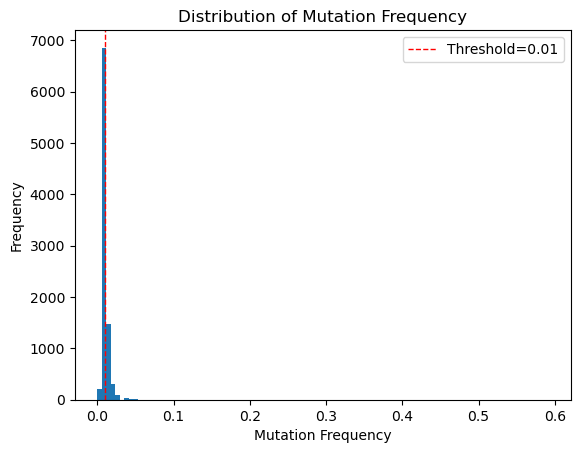

In [12]:
print("Threshold of Mutation Frequency:", threshold)
print("Number of selected features:", len(prevalence[prevalence >= threshold].index))

import matplotlib.pyplot as plt
plt.hist(prevalence, bins=100)
plt.xlabel("Mutation Frequency")
plt.ylabel("Frequency")
plt.title("Distribution of Mutation Frequency")
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold={threshold}', linewidth=1)
plt.legend()
plt.show()

In [11]:
# 套用在 testing set
test_samples = table.sample_metadata["split_42"] == "test" 
test_table = table.subset(samples=test_samples)

test_table = test_table.subset(features=high_prevalence_genes)
test_table

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
DPYD,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DCLRE1B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CRNN,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ELF3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GLI2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RBM6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CNTN3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ARMC7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


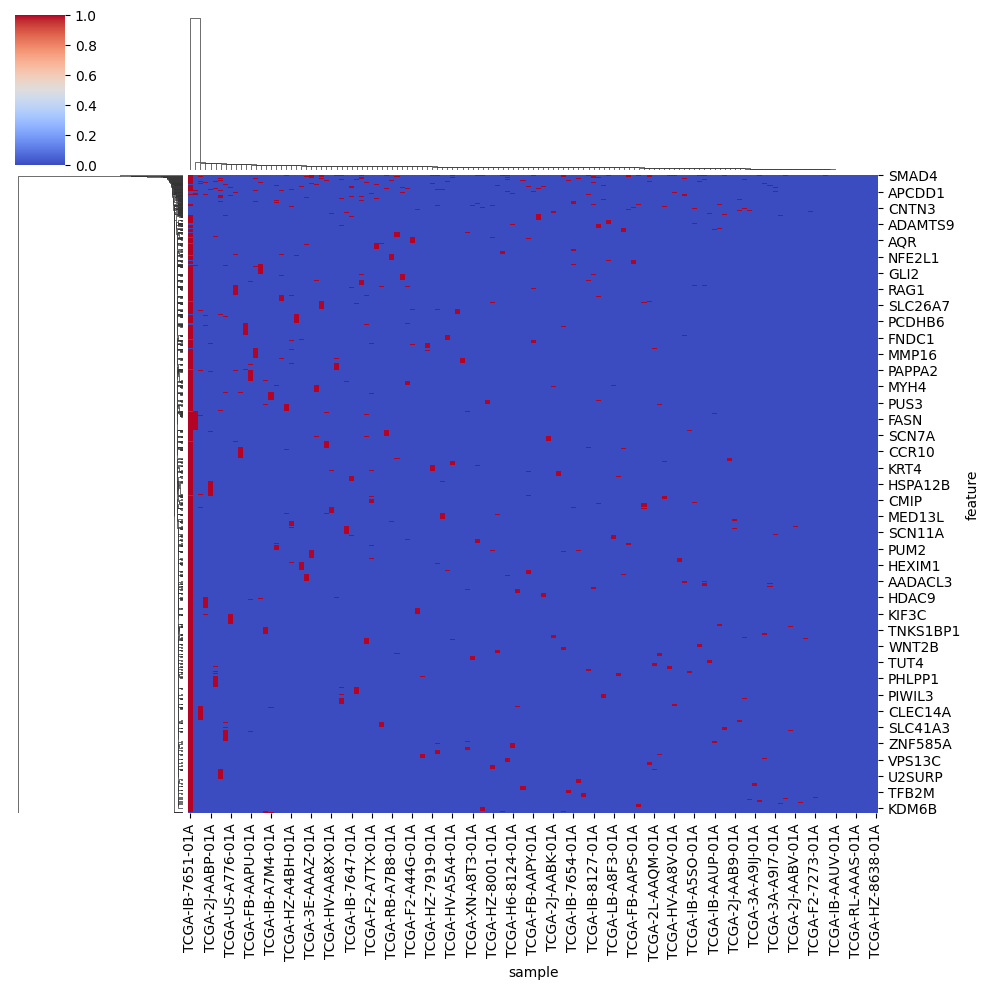

In [14]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
#train_table_small = train_table.iloc[:2000,:]
sns.clustermap(train_table, cmap="coolwarm", metric="hamming", cbar_pos=(0.02, 0.83, 0.05, 0.15))

<Axes: xlabel='sample', ylabel='feature'>

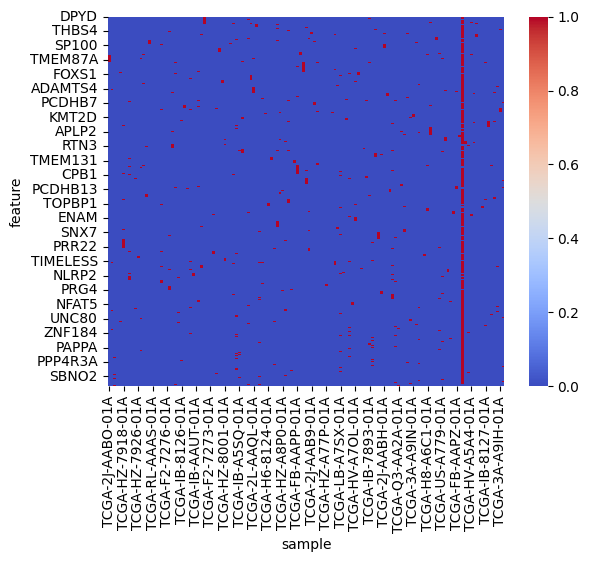

In [15]:
sns.heatmap(train_table.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm")

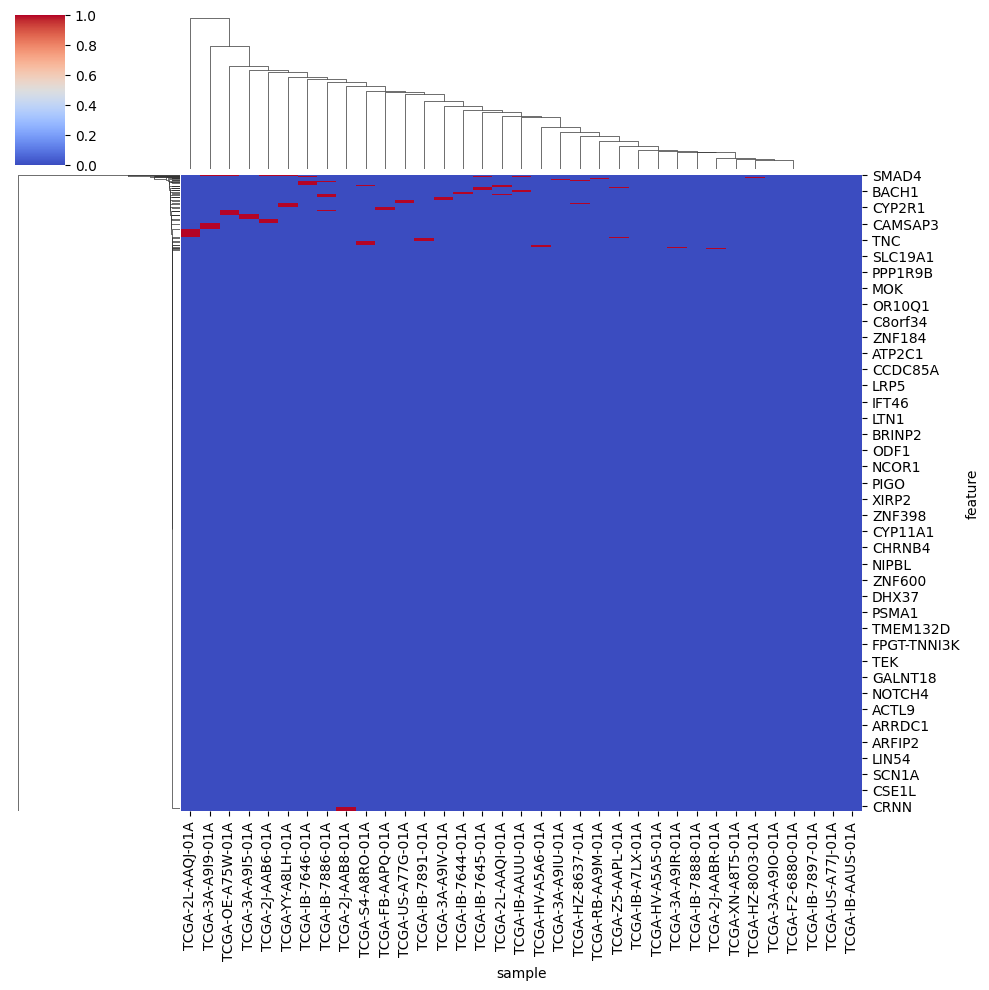

In [16]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
#test_table_small = test_table.iloc[:2000,:]
sns.clustermap(test_table, cmap="coolwarm", metric="hamming", cbar_pos=(0.02, 0.83, 0.05, 0.15))

<Axes: xlabel='sample', ylabel='feature'>

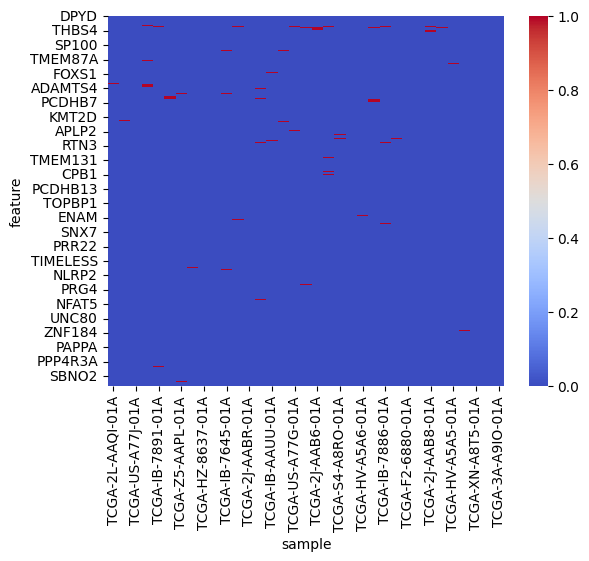

In [17]:
sns.heatmap(test_table.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm")

In [15]:
# All features performance
all_features = train_table.index
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(train_table, test_table, top_features=all_features)
print(report)

Selected top 1927 features
Best cutoff in AUROC: 0.6094480749755956
Train | F1-score: 0.961 | Accuracy: 0.971 | AUC: 0.986 | AUPRC: 0.967
Test  | F1-score: 0.348 | Accuracy: 0.571 | AUC: 0.570 | AUPRC: 0.419
              precision    recall  f1-score   support

TLS-negative      0.640     0.727     0.681        22
TLS-positive      0.400     0.308     0.348        13

    accuracy                          0.571        35
   macro avg      0.520     0.517     0.514        35
weighted avg      0.551     0.571     0.557        35



#### mRMR

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from mrmr import mrmr_classif
from sklearn.metrics import roc_auc_score

X = pd.DataFrame(train_table.T)
y = pd.Series(train_table.sample_metadata.loc[train_table.columns]["TLS"])
K_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]  # 你要選的特徵數 

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []
std_auc_scores = []
best_auc = 0
best_k = None

for K in K_list:
    auc_scores_K = []
    for train_idx, val_idx in outer_cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # 只用 training fold 做 mRMR
        selected_features = mrmr_classif(X=X_train, y=y_train, K=K)
        X_train_sel = X_train[selected_features]
        X_val_sel = X_val[selected_features]
        
        clf = RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=10
        )
        clf.fit(X_train_sel, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val_sel)[:,1])
        auc_scores_K.append(auc)
    
    mean_auc = np.mean(auc_scores_K)
    std_auc = np.std(auc_scores_K)
    auc_scores.append(mean_auc)
    std_auc_scores.append(std_auc)
    print(f"K={K}, mean AUC={mean_auc:.3f}, std={std_auc:.3f}")
    
    if mean_auc > best_auc:
        best_auc = mean_auc
        best_k = K

print(f"Best K: {best_k}, AUC: {best_auc:.3f}")

100%|██████████| 2/2 [00:00<00:00,  7.29it/s]


K=2, mean AUC=0.489, std=0.014


100%|██████████| 4/4 [00:00<00:00,  4.55it/s]


K=4, mean AUC=0.489, std=0.014


100%|██████████| 6/6 [00:01<00:00,  4.89it/s]


...

K=16, mean AUC=0.462, std=0.037


100%|██████████| 18/18 [00:04<00:00,  4.28it/s]


K=18, mean AUC=0.459, std=0.034


100%|██████████| 20/20 [00:04<00:00,  4.29it/s]


K=20, mean AUC=0.462, std=0.037
Best K: 2, AUC: 0.489


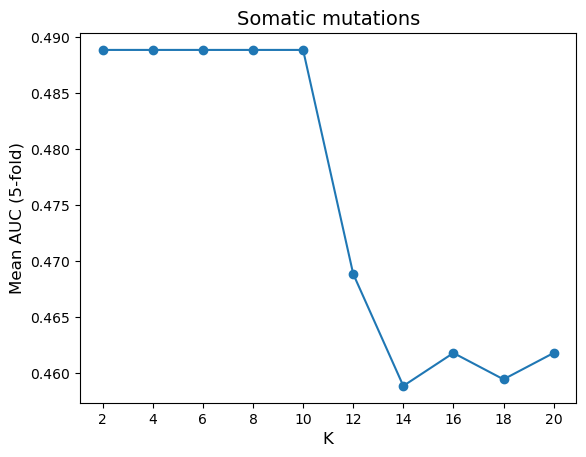

In [18]:
plt.plot(K_list, auc_scores, '-o')
plt.xlabel("K", fontsize=12)
plt.ylabel("Mean AUC (5-fold)", fontsize=12)
plt.xticks(K_list)
plt.title("Somatic mutations", fontsize=14)
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/mRMR_mutation.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Text(0.5, 1.0, 'Mean AUC with Std (5-fold)')

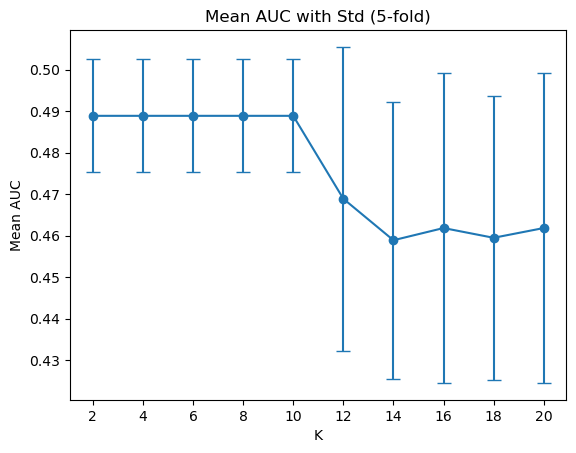

In [17]:
plt.errorbar(K_list, auc_scores, yerr=std_auc_scores, fmt='-o', capsize=5)
plt.xlabel("K")
plt.ylabel("Mean AUC")
plt.xticks(K_list)
plt.title("Mean AUC with Std (5-fold)")

In [21]:
from mrmr import mrmr_classif

top_features = mrmr_classif(
    X=pd.DataFrame(train_table.T),
    y=pd.Series(train_table.sample_metadata.loc[train_table.columns]["TLS"]),
    K=best_k  # 要選幾個
)

np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_mut_mrmr.npy", top_features)
print(top_features)

100%|██████████| 2/2 [00:00<00:00,  6.98it/s]

['DDX31', 'ARMC7']


#### Feature Importance (Run 100*100 times)

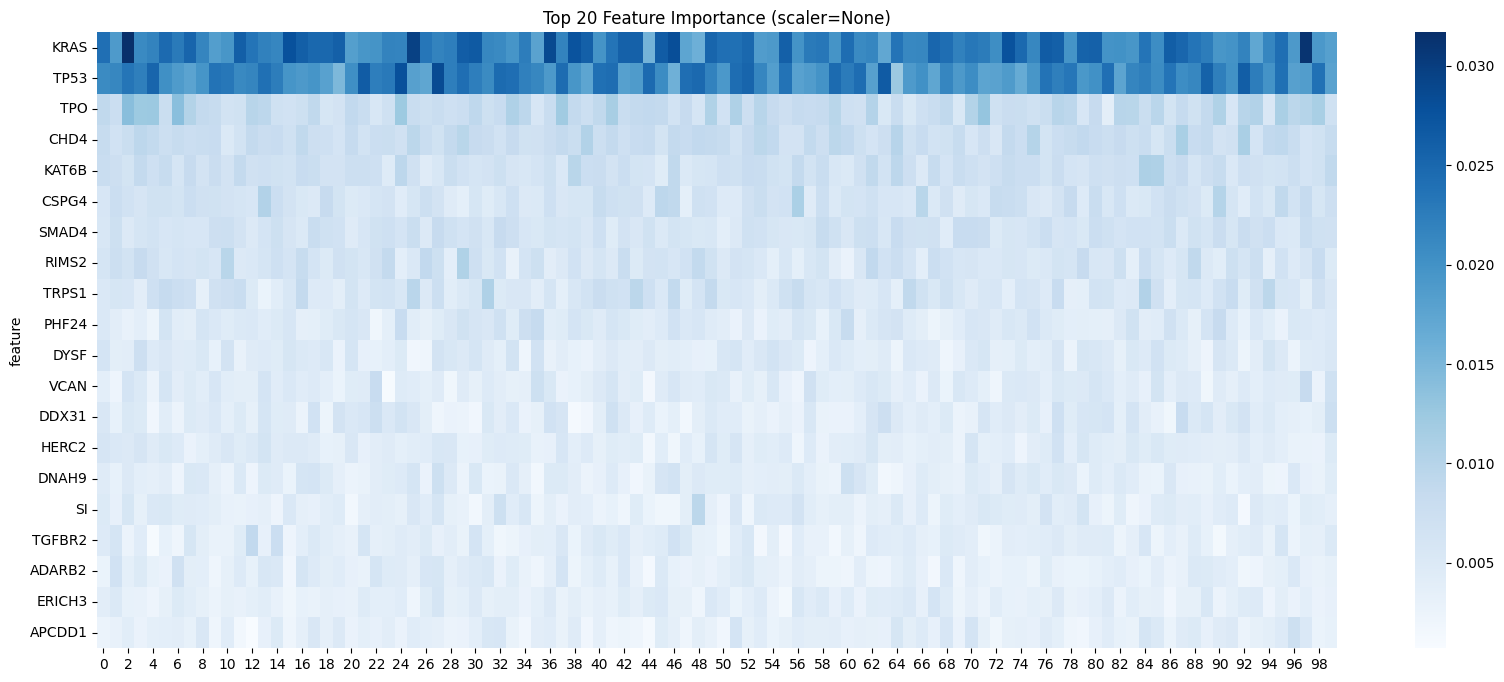

feature
KRAS      0.022738
TP53       0.02126
TPO       0.008467
CHD4       0.00786
KAT6B     0.007114
CSPG4     0.006445
SMAD4     0.006404
RIMS2     0.006106
TRPS1     0.005998
PHF24     0.004892
DYSF      0.004495
VCAN      0.004405
DDX31     0.004387
HERC2     0.004273
DNAH9     0.004042
SI        0.003995
TGFBR2    0.003917
ADARB2     0.00372
ERICH3    0.003708
APCDD1    0.003644
dtype: object


In [ ]:
from model_utils import run_feature_importance
global_importance = run_feature_importance(train_table, run_seeds=100,
                                           save_path="/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/mut_importance.csv", plot_top=20)
print(global_importance.head(20))

#### Choose cutoff for selected features

In [ ]:
# import pandas as pd
# importance_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/mut_importance.csv", index_col=0)
# global_importance = importance_df.mean(axis=1).sort_values(ascending=False)
# global_importance = global_importance.astype(object)   # 將資料型別轉換為 object (防止 knee_x 出現小數點)
# print(global_importance.head(20))

feature
KRAS      0.022738
TP53       0.02126
TPO       0.008467
CHD4       0.00786
KAT6B     0.007114
CSPG4     0.006445
SMAD4     0.006404
RIMS2     0.006106
TRPS1     0.005998
PHF24     0.004892
DYSF      0.004495
VCAN      0.004405
DDX31     0.004387
HERC2     0.004273
DNAH9     0.004042
SI        0.003995
TGFBR2    0.003917
ADARB2     0.00372
ERICH3    0.003708
APCDD1    0.003644
dtype: object


/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Elbow point (Feature top n): 10


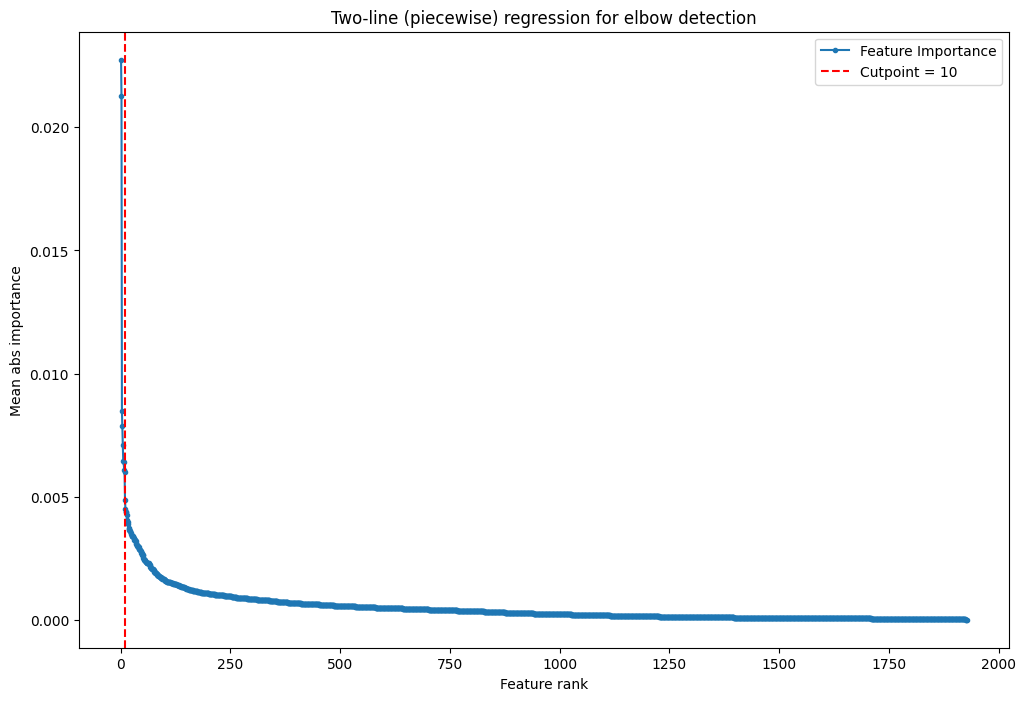

In [14]:
from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)

In [15]:
top_features = global_importance.head(knee_x).index
#np.save("/home/data/data_YM313112004/TLS_model/results/selected_features/top_features_mut.npy", top_features)
print(top_features)

# top_features = np.load("/home/data/data_YM313112004/TLS_model/results/selected_features/top_features_mut.npy", allow_pickle=True)
# top_features

Index(['KRAS', 'TP53', 'TPO', 'CHD4', 'KAT6B', 'CSPG4', 'SMAD4', 'RIMS2',
       'TRPS1', 'PHF24'],
      dtype='object', name='feature')


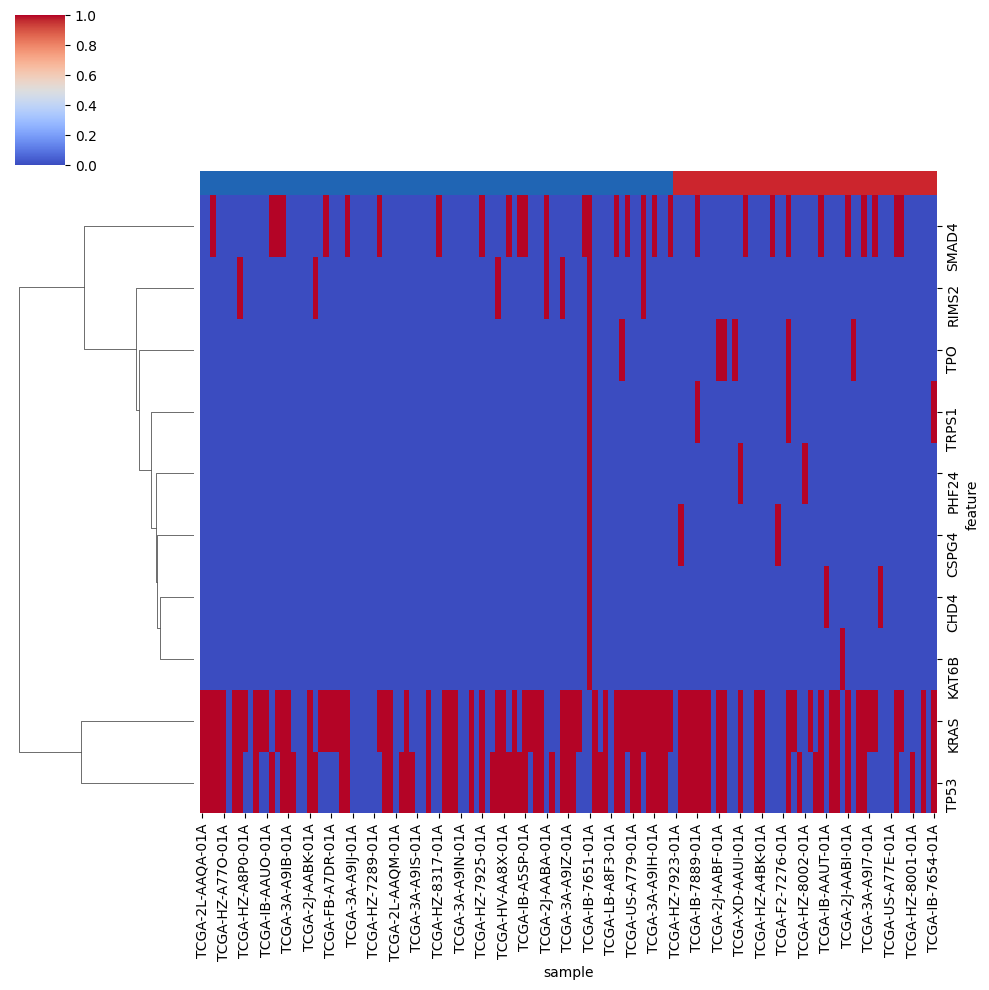

In [23]:
from matplotlib.colors import ListedColormap

# 提取 TLS 標籤並創建顏色分類
train_subseted = train_table.subset(features=top_features)
tls_labels = train_subseted.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
train_subseted_sorted = train_subseted.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(train_subseted_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

In [24]:
train_table.subset(features=top_features).feature_metadata

,AlteredSamples,BIOTYPE,Entrez_Gene_Id,Frame_Shift_Del,Frame_Shift_Ins,Gene,GeneID,In_Frame_Del,In_Frame_Ins,Missense_Mutation,...,gene_type,havana_gene,hgnc_id,level,phase,score,source,start,strand,total
feature,,,,,,,,,,,,,,,,,,,,,
KRAS,99,protein_coding,3845,0,0,ENSG00000133703,ENSG00000133703,0,0,100,...,protein_coding,OTTHUMG00000171193.4,HGNC:6407,2,.,.,HAVANA,25205246,-,100
TP53,95,protein_coding,7157,10,6,ENSG00000141510,ENSG00000141510,0,1,58,...,protein_coding,OTTHUMG00000162125.10,HGNC:11998,2,.,.,HAVANA,7661779,-,95
TPO,7,protein_coding,7173,0,0,ENSG00000115705,ENSG00000115705,0,0,6,...,protein_coding,OTTHUMG00000090271.11,HGNC:12015,2,.,.,HAVANA,1374066,+,7
CHD4,3,protein_coding,1108,0,0,ENSG00000111642,ENSG00000111642,0,0,3,...,protein_coding,OTTHUMG00000169164.13,HGNC:1919,2,.,.,HAVANA,6570082,-,5
KAT6B,2,protein_coding,23522,0,0,ENSG00000156650,ENSG00000156650,0,0,4,...,protein_coding,OTTHUMG00000018509.9,HGNC:17582,2,.,.,HAVANA,74824927,+,4
CSPG4,3,protein_coding,1464,0,0,ENSG00000173546,ENSG00000173546,0,0,5,...,protein_coding,OTTHUMG00000142836.1,HGNC:2466,2,.,.,HAVANA,75674322,-,6
SMAD4,36,protein_coding,4089,7,3,ENSG00000141646,ENSG00000141646,1,0,15,...,protein_coding,OTTHUMG00000132696.11,HGNC:6770,1,.,.,HAVANA,51028394,+,37
RIMS2,7,protein_coding,9699,0,0,ENSG00000176406,ENSG00000176406,0,0,7,...,protein_coding,OTTHUMG00000162097.12,HGNC:17283,1,.,.,HAVANA,103500696,+,7
TRPS1,4,protein_coding,7227,0,1,ENSG00000104447,ENSG00000104447,0,0,4,...,protein_coding,OTTHUMG00000142829.6,HGNC:12340,1,.,.,HAVANA,115408496,-,5


#### Model Evaluation

In [22]:
# Evaluation on test dataset
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff  = evaluate_model(train_table, test_table, top_features=top_features)
print(report)

Selected top 2 features
Best cutoff in AUROC: 0.9481290627539097
Train | F1-score: 0.185 | Accuracy: 0.679 | AUC: 0.551 | AUPRC: 0.423
Test  | F1-score: 0.000 | Accuracy: 0.629 | AUC: 0.500 | AUPRC: 0.371
              precision    recall  f1-score   support

TLS-negative      0.629     1.000     0.772        22
TLS-positive      0.000     0.000     0.000        13

    accuracy                          0.629        35
   macro avg      0.314     0.500     0.386        35
weighted avg      0.395     0.629     0.485        35

